# NYC Airbnb — OSPI projekat

Analiza podataka o Airbnb smeštajima u Njujorku (skup podataka *New York City Airbnb Open Data*, `AB_NYC_2019.csv`).

**Istraživačka pitanja:**
1. Možemo li predvideti cenu listinga na osnovu njegovih karakteristika? (Regresija)
2. Da li možemo klasifikovati listing u cenovnu kategoriju? (Klasifikacija)
3. Koje grupe listinga postoje na osnovu njihovih karakteristika? (Klasterovanje)

Importovanje neophodnih biblioteka. Pandas nam je poznat za rad sa podacima, matplotlib i seaborn za vizualizaciju, dok se sklearn koristi kao machine learning biblioteka u Pythonu.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score,
                              precision_score, recall_score, f1_score,
                              classification_report, confusion_matrix,
                              silhouette_score)
from sklearn.cluster import KMeans
from math import sqrt

%matplotlib inline

Učitavanje podataka iz CSV fajla. Fajl `AB_NYC_2019.csv` treba da se nalazi u istom folderu kao i ovaj notebook.

In [ ]:
data = pd.read_csv('AB_NYC_2019.csv')

OPIS PODATAKA

Svaki red predstavlja jedan Airbnb listing u Njujorku, sa informacijama o lokaciji, ceni, tipu smeštaja, broju recenzija i dostupnosti u toku godine.

Pregled broja kolona i redova iz skupa podataka.

In [ ]:
data.shape

Kratak uvid u podatke.

In [ ]:
data.head()

Informacije o tipovima podataka i broju nedostajućih vrednosti po koloni.

In [ ]:
data.info()

## Priprema podataka

Pre analize je potrebno očistiti podatke: ukloniti outliere u ceni (listinge sa cenom 0 ili preko 1000 dolara), popuniti nedostajuće vrednosti i pripremiti kolone za dalju analizu.

Uklanjanje outliera — zadržavamo samo listinge sa cenom između 0 i 1000 dolara (isključivo).

In [ ]:
before_rows = data.shape[0]
data = data[(data['price'] > 0) & (data['price'] <= 1000)]
after_rows = data.shape[0]
print('Uklonjeno redova:', before_rows - after_rows)

Popunjavanje nedostajućih vrednosti kolone `reviews_per_month` nulom, pošto NaN u ovom slučaju znači da listing nema recenzija.

In [ ]:
data['reviews_per_month'] = data['reviews_per_month'].fillna(0)

Provera preostalih nedostajućih vrednosti po kolonama koje su nam potrebne za analizu.

In [8]:
data[['name', 'host_name', 'last_review']].isnull().sum()

name             16
host_name        21
last_review    9919
dtype: int64

Kolone `name`, `host_name` i `last_review` nisu ključne za modele koje pravimo, pa nedostajuće vrednosti u njima ne uklanjamo iz celog skupa podataka.

Kreiranje uslovne kolone `price_category` na osnovu cene (koristi se i u Power BI izveštaju kao Price_Category).

In [9]:
def price_category(price):
    if price <= 69:
        return 'Budget'
    elif price <= 150:
        return 'Mid-Range'
    else:
        return 'Luxury'

data['price_category'] = data['price'].apply(price_category)
data['price_category'].value_counts()

price_category
Mid-Range    21586
Luxury       14699
Budget       12360
Name: count, dtype: int64

Label encoding kategoričkih obeležja (`neighbourhood_group` i `room_type`) kako bi mogli da se koriste u modelima mašinskog učenja.

In [10]:
le_group = LabelEncoder()
le_room = LabelEncoder()

data['neighbourhood_group_enc'] = le_group.fit_transform(data['neighbourhood_group'])
data['room_type_enc'] = le_room.fit_transform(data['room_type'])

data[['neighbourhood_group', 'neighbourhood_group_enc', 'room_type', 'room_type_enc']].head()

,neighbourhood_group,neighbourhood_group_enc,room_type,room_type_enc
0,Brooklyn,1,Private room,1
1,Manhattan,2,Entire home/apt,0
2,Manhattan,2,Private room,1
3,Brooklyn,1,Entire home/apt,0
4,Manhattan,2,Entire home/apt,0


## EDA (Eksplorativna analiza podataka)

Distribucija listinga po kvartovima (neighbourhood_group).

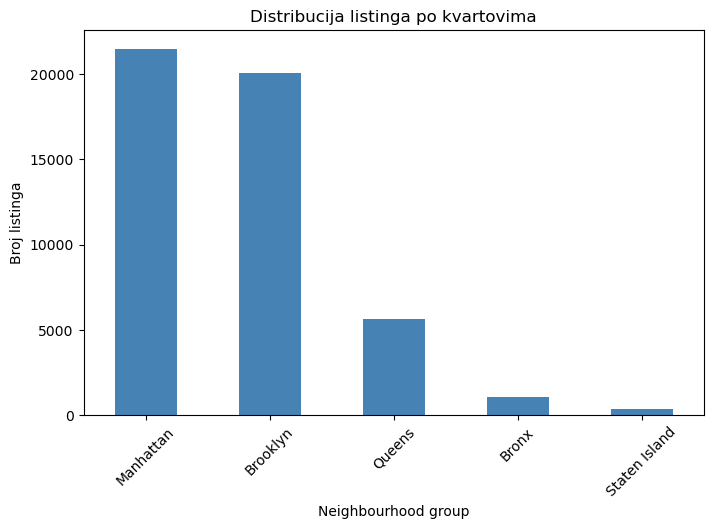

In [11]:
plt.figure(figsize=(8,5))
data['neighbourhood_group'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Distribucija listinga po kvartovima')
plt.xlabel('Neighbourhood group')
plt.ylabel('Broj listinga')
plt.xticks(rotation=45)
plt.show()

Distribucija tipova smeštaja (room_type).

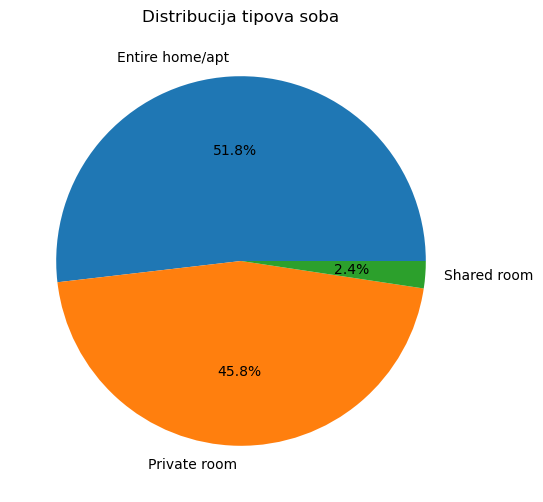

In [12]:
plt.figure(figsize=(6,6))
data['room_type'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Distribucija tipova soba')
plt.ylabel('')
plt.show()

Distribucija cena listinga.

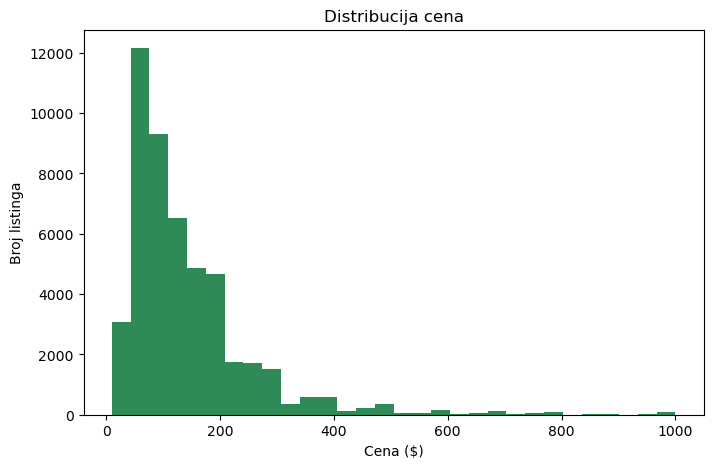

In [13]:
plt.figure(figsize=(8,5))
plt.hist(data['price'], bins=30, color='seagreen')
plt.title('Distribucija cena')
plt.xlabel('Cena ($)')
plt.ylabel('Broj listinga')
plt.show()

Medijana cene po kvartu i tipu sobe.

In [14]:
data.groupby(['neighbourhood_group', 'room_type'])['price'].median().unstack()

room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,100.0,53.5,40.0
Brooklyn,145.0,65.0,36.0
Manhattan,190.0,90.0,69.0
Queens,120.0,60.0,37.0
Staten Island,100.0,50.0,30.0


Korelaciona matrica numeričkih obeležja.

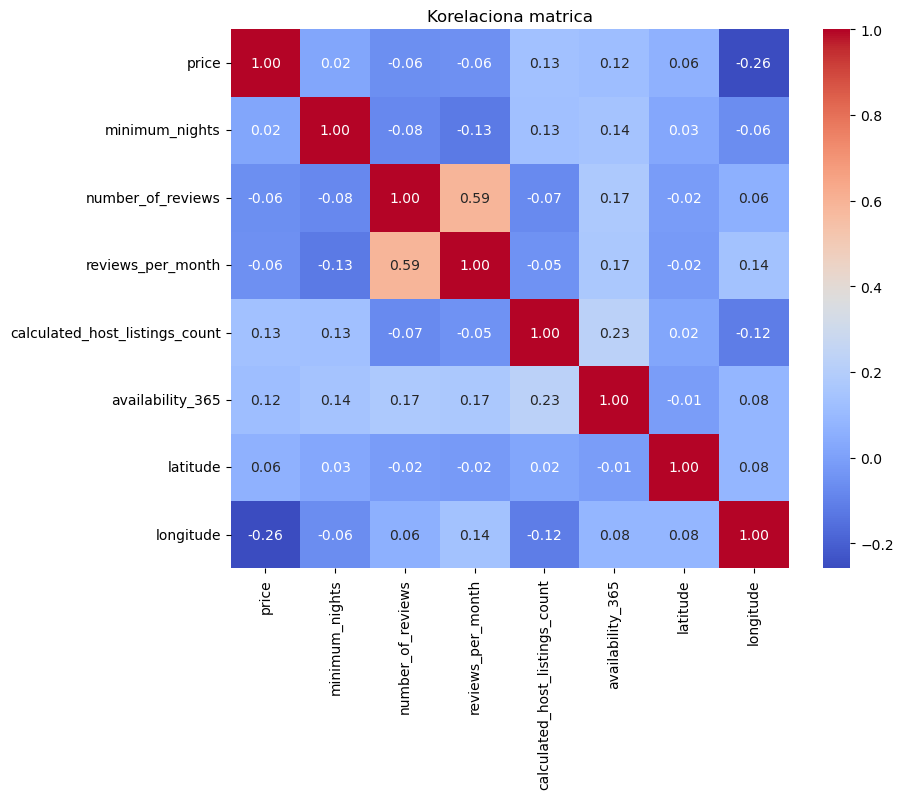

In [15]:
numeric_cols = ['price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month',
                'calculated_host_listings_count', 'availability_365', 'latitude', 'longitude']

plt.figure(figsize=(9,7))
sns.heatmap(data[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Korelaciona matrica')
plt.show()

## Model 1 — Regresija (predikcija cene)

**Istraživačko pitanje:** Možemo li predvideti cenu Airbnb listinga na osnovu njegovih karakteristika (lokacija, tip sobe, minimalan broj noćenja, broj recenzija i dostupnost)?

**Zašto regresija?** Cena (`price`) je kontinuirana numerička promenljiva — može uzeti bilo koju vrednost u određenom opsegu, a ne pripada unapred definisanim kategorijama. Regresija je metoda namenjena upravo predikciji ovakvih numeričkih ciljnih promenljivih, za razliku od klasifikacije koja predviđa diskretne klase.

Biramo obeležja (features) i ciljnu promenljivu (target) za regresioni model.

In [16]:
features_reg = ['neighbourhood_group_enc', 'room_type_enc', 'minimum_nights',
                'number_of_reviews', 'reviews_per_month',
                'calculated_host_listings_count', 'availability_365',
                'latitude', 'longitude']
target_reg = 'price'

X = data[features_reg]
y = data[target_reg]

Delimo podatke na trening i test skup.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Standardizacija numeričkih obeležja pomoću StandardScaler-a.

In [18]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Kreiramo model zasnovan na linearnoj regresiji i treniramo ga.

In [19]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

y_pred_lin = lin_reg.predict(X_test_scaled)

Evaluacija Linear Regression modela pomoću RMSE i R² metrika.

In [20]:
rmse_lin = sqrt(mean_squared_error(y_test, y_pred_lin))
r2_lin = r2_score(y_test, y_pred_lin)

print('Linear Regression')
print('RMSE:', round(rmse_lin, 2))
print('R2:', round(r2_lin, 3))

Linear Regression
RMSE: 99.53
R2: 0.29


Kreiramo drugi regresioni model — Random Forest Regressor — koji obično bolje hvata nelinearne odnose u podacima.

In [21]:
rf_reg = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42)
rf_reg.fit(X_train, y_train)

y_pred_rf = rf_reg.predict(X_test)

Evaluacija Random Forest Regressor modela.

In [22]:
rmse_rf = sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print('Random Forest Regressor')
print('RMSE:', round(rmse_rf, 2))
print('R2:', round(r2_rf, 3))

Random Forest Regressor
RMSE: 86.87
R2: 0.459


Feature importance — koja obeležja najviše doprinose predikciji cene.

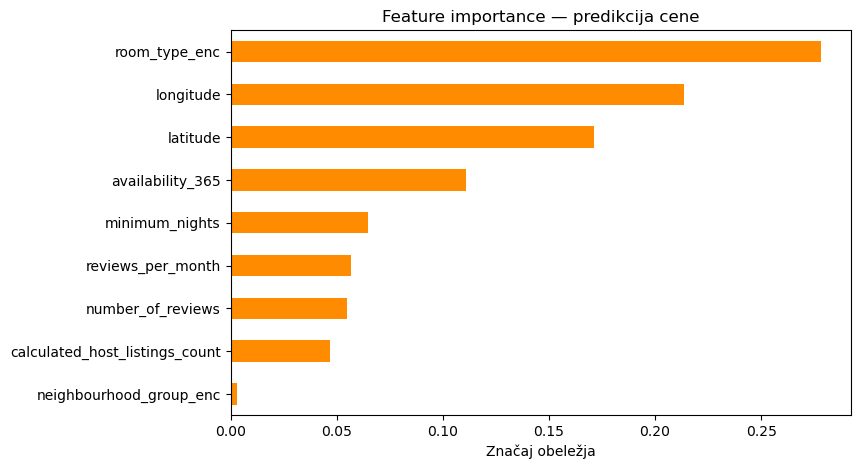

In [23]:
importances = pd.Series(rf_reg.feature_importances_, index=features_reg).sort_values(ascending=False)

plt.figure(figsize=(8,5))
importances.plot(kind='barh', color='darkorange')
plt.title('Feature importance — predikcija cene')
plt.xlabel('Značaj obeležja')
plt.gca().invert_yaxis()
plt.show()

Poređenje stvarnih i predviđenih cena na test skupu (Random Forest model).

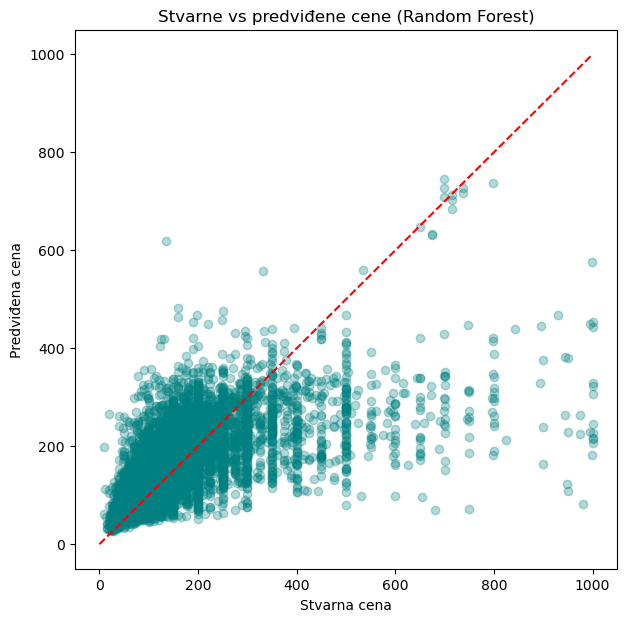

In [24]:
plt.figure(figsize=(7,7))
plt.scatter(y_test, y_pred_rf, alpha=0.3, color='teal')
plt.plot([0, 1000], [0, 1000], color='red', linestyle='--')
plt.xlabel('Stvarna cena')
plt.ylabel('Predviđena cena')
plt.title('Stvarne vs predviđene cene (Random Forest)')
plt.show()

**Interpretacija:** Poredeći RMSE i R² vrednosti oba modela, Random Forest Regressor obično ostvaruje niži RMSE i viši R² od Linear Regression modela, što znači da bolje objašnjava varijacije u ceni. Niži RMSE znači manju prosečnu grešku predikcije u dolarima, a viši R² znači da model objašnjava veći procenat varijanse cene. Ipak, s obzirom na R² vrednost, model ne objašnjava celokupnu varijaciju cene — to je očekivano jer cena zavisi i od faktora koji nisu sadržani u ovom skupu podataka (npr. kvalitet fotografija, opremljenost stana, sezona).

## Model 2 — Klasifikacija (predikcija cenovne kategorije)

**Istraživačko pitanje:** Da li možemo klasifikovati listing u cenovnu kategoriju (Budget / Mid-Range / Luxury) na osnovu njegovih karakteristika?

**Zašto klasifikacija?** Ciljna promenljiva `price_category` je kategorička sa tri unapred definisane klase (Budget, Mid-Range, Luxury), a ne kontinuirana vrednost. Klasifikacija je metoda koja modelu omogućava da nauči granice između diskretnih klasa na osnovu obeležja, za razliku od regresije koja predviđa numeričku vrednost.

Provera broja instanci po klasi.

In [25]:
data['price_category'].value_counts()

price_category
Mid-Range    21586
Luxury       14699
Budget       12360
Name: count, dtype: int64

Biramo obeležja i ciljnu promenljivu za klasifikacioni model. Cenu ne uključujemo u obeležja jer je ona direktno korišćena za kreiranje ciljne promenljive.

In [26]:
features_clf = ['neighbourhood_group_enc', 'room_type_enc', 'minimum_nights',
                'number_of_reviews', 'reviews_per_month',
                'calculated_host_listings_count', 'availability_365',
                'latitude', 'longitude']
target_clf = 'price_category'

X_clf = data[features_clf]
y_clf = data[target_clf]

Delimo podatke na trening i test skup.

In [27]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

Kreiramo model za klasifikaciju pomoću Random Forest Classifier-a i treniramo ga.

In [28]:
rf_clf = RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42)
rf_clf.fit(X_train_c, y_train_c)

predictions = rf_clf.predict(X_test_c)

Evaluacija modela pomoću accuracy, precision, recall i F1 metrika.

In [29]:
accuracy = accuracy_score(y_test_c, predictions)
precision = precision_score(y_test_c, predictions, average='weighted')
recall = recall_score(y_test_c, predictions, average='weighted')
f1 = f1_score(y_test_c, predictions, average='weighted')

print('Accuracy:', round(accuracy, 3))
print('Precision:', round(precision, 3))
print('Recall:', round(recall, 3))
print('F1 score:', round(f1, 3))
print()
print(classification_report(y_test_c, predictions))

Accuracy: 0.705
Precision: 0.706
Recall: 0.705
F1 score: 0.705

              precision    recall  f1-score   support

      Budget       0.72      0.77      0.74      2472
      Luxury       0.74      0.69      0.72      2940
   Mid-Range       0.67      0.67      0.67      4317

    accuracy                           0.71      9729
   macro avg       0.71      0.71      0.71      9729
weighted avg       0.71      0.71      0.70      9729



Confusion matrix — prikaz gde model najčešće greši između klasa.

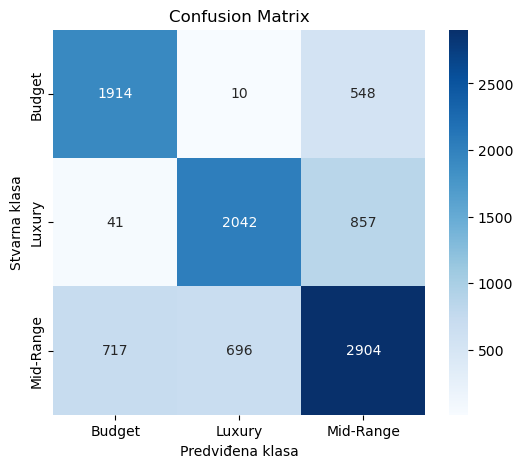

In [30]:
cm = confusion_matrix(y_test_c, predictions, labels=rf_clf.classes_)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=rf_clf.classes_, yticklabels=rf_clf.classes_)
plt.xlabel('Predviđena klasa')
plt.ylabel('Stvarna klasa')
plt.title('Confusion Matrix')
plt.show()

**Interpretacija:** Accuracy pokazuje procenat ukupno tačno klasifikovanih listinga. Precision govori koliko je model pouzdan kada predvidi određenu klasu, dok recall govori koliki procenat stvarnih instanci te klase je model uspeo da prepozna. F1 score predstavlja balans između precision i recall. Na osnovu confusion matrice možemo videti da li model najčešće greši između susednih kategorija (npr. Mid-Range i Luxury), što je očekivano jer se cene na granicama kategorija najteže razlikuju.

## Model 3 — K-Means klasterovanje

**Istraživačko pitanje:** Koje grupe (klastere) listinga možemo identifikovati na osnovu cene, dostupnosti, broja recenzija i lokacije?

**Zašto klasterovanje?** Za razliku od prethodna dva modela, ovde nemamo unapred poznatu ciljnu promenljivu (labelu) koju bismo predviđali — cilj je da algoritam sam otkrije prirodnu strukturu i grupe unutar podataka na osnovu sličnosti listinga. K-Means je metoda nenadgledanog učenja (unsupervised learning) koja je namenjena upravo ovakvim problemima grupisanja bez unapred definisanih klasa.

Biramo obeležja za klasterovanje.

In [31]:
features_cluster = ['price', 'availability_365', 'number_of_reviews', 'latitude', 'longitude', 'minimum_nights']
select_df = data[features_cluster]

Standardizacija podataka je neophodna jer su obeležja u različitim skalama (npr. cena je u desetinama/stotinama, dok su koordinate u opsegu 40–41).

In [32]:
scaler_cluster = StandardScaler()
X_cluster = scaler_cluster.fit_transform(select_df)

Elbow metoda za određivanje optimalnog broja klastera — posmatramo inerciju (sumu kvadrata udaljenosti) za različit broj klastera.

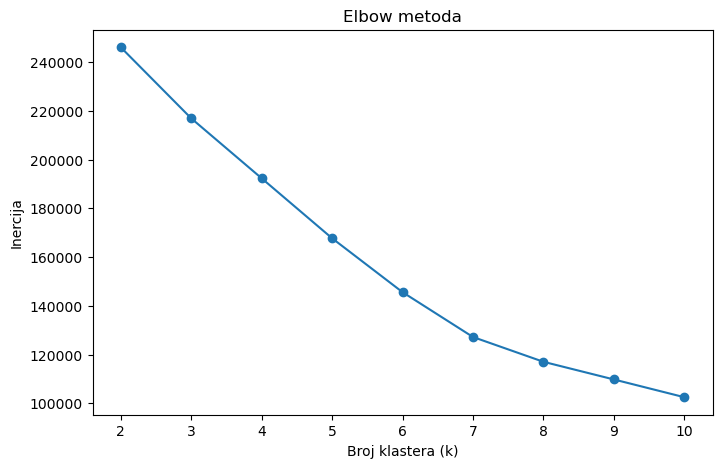

In [33]:
inertia = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster)
    inertia.append(km.inertia_)

plt.figure(figsize=(8,5))
plt.plot(list(K_range), inertia, marker='o')
plt.xlabel('Broj klastera (k)')
plt.ylabel('Inercija')
plt.title('Elbow metoda')
plt.show()

Silhouette score za različit broj klastera — što je vrednost bliža 1, to su klasteri bolje definisani.

In [ ]:
silhouette_scores = []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster)
    score = silhouette_score(X_cluster, labels)
    silhouette_scores.append(score)
    print(f'k={k}, silhouette score={round(score, 3)}')

plt.figure(figsize=(8,5))
plt.plot(list(K_range), silhouette_scores, marker='o', color='purple')
plt.xlabel('Broj klastera (k)')
plt.ylabel('Silhouette score')
plt.title('Silhouette score po broju klastera')
plt.show()

k=2, silhouette score=0.271


Na osnovu elbow metode i silhouette score-a, biramo k=4 kao optimalan broj klastera. Kreiramo finalni model.

In [ ]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
data['cluster'] = kmeans.fit_predict(X_cluster)

data['cluster'].value_counts()

Geografska mapa klastera — vizuelni prikaz raspodele klastera po koordinatama listinga.

In [ ]:
plt.figure(figsize=(9,8))
scatter = plt.scatter(data['longitude'], data['latitude'], c=data['cluster'], cmap='tab10', alpha=0.4, s=8)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Geografska mapa klastera')
plt.legend(*scatter.legend_elements(), title='Klaster')
plt.show()

Distribucija klastera po kvartu (neighbourhood_group).

In [ ]:
cluster_by_group = data.groupby(['neighbourhood_group', 'cluster']).size().unstack(fill_value=0)
cluster_by_group

In [ ]:
cluster_by_group.plot(kind='bar', stacked=True, figsize=(9,6), colormap='tab10')
plt.title('Distribucija klastera po kvartu')
plt.xlabel('Neighbourhood group')
plt.ylabel('Broj listinga')
plt.xticks(rotation=45)
plt.legend(title='Klaster')
plt.show()

Prosečne vrednosti obeležja po klasteru — pomaže u interpretaciji šta svaki klaster predstavlja.

In [ ]:
data.groupby('cluster')[features_cluster].mean()

**Interpretacija:** Na osnovu prosečnih vrednosti po klasteru možemo opisati profil svake grupe listinga — npr. jedan klaster može predstavljati jeftine listinge sa visokom dostupnošću tokom godine (verovatno investicioni Airbnb objekti), dok drugi može predstavljati skuplje listinge sa malim brojem recenzija (novi ili luksuzni objekti). Geografska mapa pokazuje da li su klasteri prostorno koncentrisani u određenim delovima grada, što može ukazivati na to da lokacija igra značajnu ulogu u formiranju ovih grupa.

## Zaključak

U ovom notebook-u smo:
- Pripremili i očistili NYC Airbnb skup podataka (uklanjanje outliera, popunjavanje nedostajućih vrednosti, kreiranje uslovne kolone price_category, label encoding).
- Sproveli eksplorativnu analizu podataka (distribucije, korelaciona matrica).
- Kreirali regresione modele (Linear Regression i Random Forest Regressor) za predikciju cene.
- Kreirali klasifikacioni model (Random Forest Classifier) za predikciju cenovne kategorije.
- Sproveli K-Means klasterovanje kako bismo identifikovali prirodne grupe listinga.

Rezultati pokazuju da je moguće delimično predvideti cenu i cenovnu kategoriju na osnovu lokacije, tipa smeštaja i drugih karakteristika, dok klasterovanje otkriva prirodne grupe listinga koje se razlikuju po ceni, dostupnosti i geografskoj lokaciji.